# Facial Recognition: Image Processing and Model

**Owner:** Ayo. **Part of:** User Identity and Product Recommendation System (step 1: face authentication).

This section covers:
1. Display sample images of every member
2. Detect and align faces
3. Apply augmentations (rotation, flip, grayscale, brightness/contrast) to every image
4. Extract features and save `image_features.csv`
5. Train and evaluate the facial recognition model (accuracy, F1-score, log loss)
6. Reject unauthorized faces and expose a `predict()` function for the command-line app

All logic lives in `face_model.py`. This notebook imports it, so the notebook and the CLI app use exactly the same code.

In [1]:
import os
os.environ["OPENCV_LOG_LEVEL"] = "ERROR"  # hide OpenCV DNN backend warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

import face_model as fm

pd.set_option('display.precision', 3)
sources = fm.list_photos()
sources['image_size'] = [cv2.imread(str(fm.ROOT / s)).shape[1::-1] for s in sources.source_id]
display(sources)
display(pd.crosstab(sources.member, sources.expression))

,source_id,member,expression,image_size
0,armstrong/armstrong_happy.jpeg,armstrong,happy,"(960, 1280)"
1,armstrong/armstrong_neutral.jpeg,armstrong,neutral,"(960, 1280)"
2,armstrong/armstrong_surprised.jpeg,armstrong,surprised,"(960, 1280)"
3,ayoo/ayoo_happy.jpg,ayoo,happy,"(400, 400)"
4,ayoo/ayoo_neutral.jpeg,ayoo,neutral,"(960, 1280)"
5,ayoo/ayoo_surprised.jpeg,ayoo,surprised,"(960, 1280)"
6,diane/diane_happy.jpeg,diane,happy,"(822, 1280)"
7,diane/diane_neutral.jpeg,diane,neutral,"(889, 888)"
8,diane/diane_surprised.jpeg,diane,surprised,"(1280, 720)"
9,fadhili/fadhili_happy.jpeg,fadhili,happy,"(1117, 1600)"


expression,happy,neutral,surprised
member,,,
armstrong,1,1,1
ayoo,1,1,1
diane,1,1,1
fadhili,1,1,1


## 1. Sample images of every member

Four members, each with a neutral, happy (smiling), and surprised photo: **12 original images**, named `<member>/<member>_<expression>.jpeg`.
The photos come from different phones and framings (sizes above range from 400×400 to 1117×1600, portrait and landscape; one is a full-body graduation shot). This variation is why we detect and crop the face before extracting features. Otherwise the model would partly learn backgrounds and clothing.

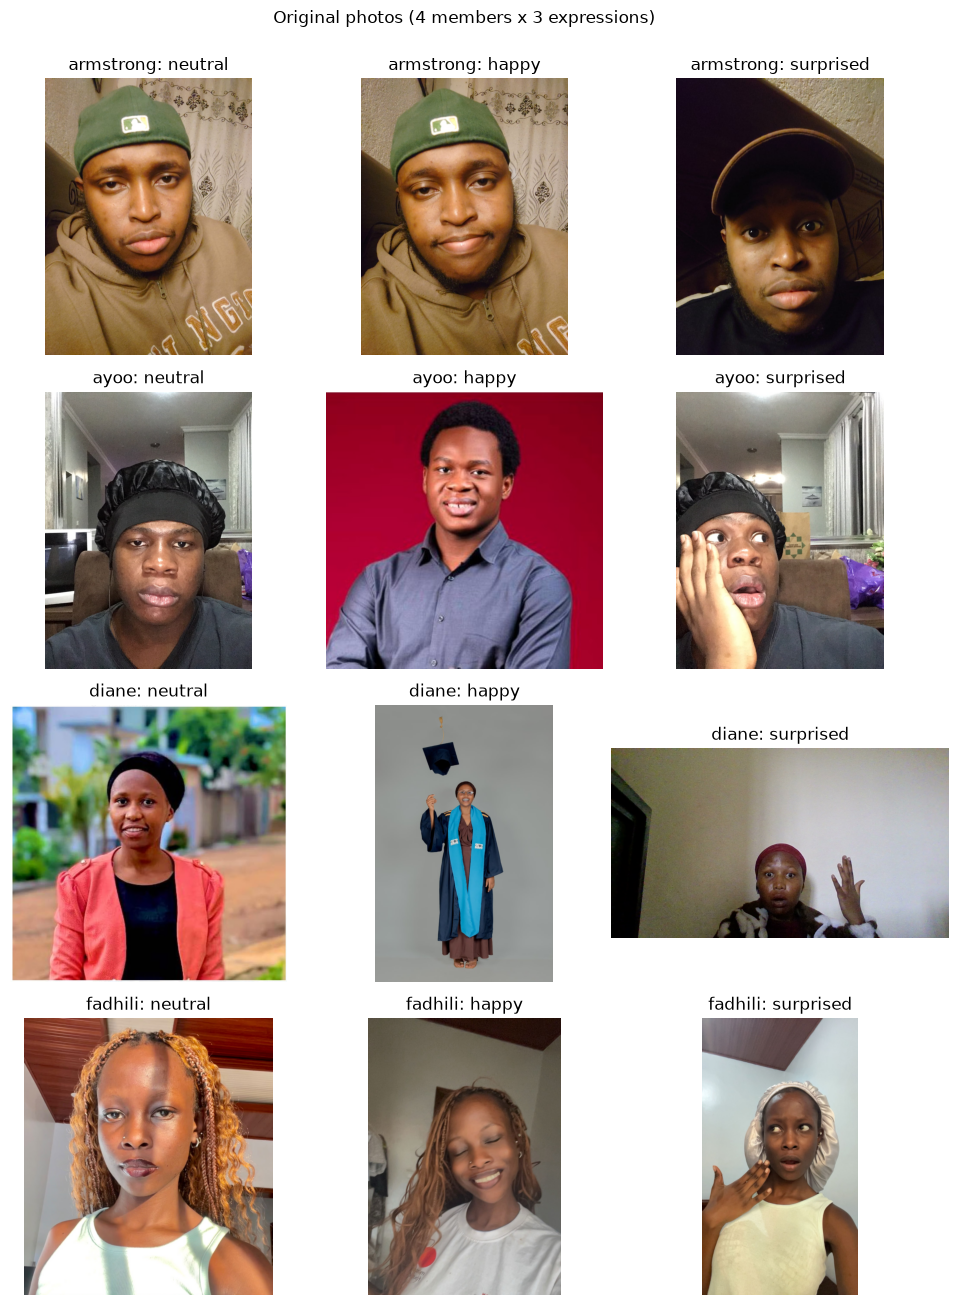

In [2]:
fig, axes = plt.subplots(len(fm.MEMBERS), 3, figsize=(10, 13))
for r, member in enumerate(fm.MEMBERS):
    for c, expr in enumerate(fm.EXPRESSIONS):
        src = sources[(sources.member == member) & (sources.expression == expr)].iloc[0]
        axes[r, c].imshow(cv2.cvtColor(fm.load_image(fm.ROOT / src.source_id), cv2.COLOR_BGR2RGB))
        axes[r, c].set_title(f'{member}: {expr}')
        axes[r, c].axis('off')
plt.suptitle('Original photos (4 members x 3 expressions)', y=1.0)
plt.tight_layout()
plt.show()

## 2. Face detection and alignment

We use two **pretrained OpenCV networks** (from the official OpenCV model zoo, stored in `models/`). Neither is trained on our data:

- **YuNet** detects faces and five landmarks (eyes, nose, mouth corners).
- **SFace** uses those landmarks to rotate and crop each face to a standard 112×112 alignment, then turns it into a 128-number identity embedding.

An earlier attempt with a Haar cascade + HOG features reached only ~58% accuracy (25% is random guessing for four members). The Haar cascade also missed the small face in `diane_happy`. YuNet finds all 12 faces.

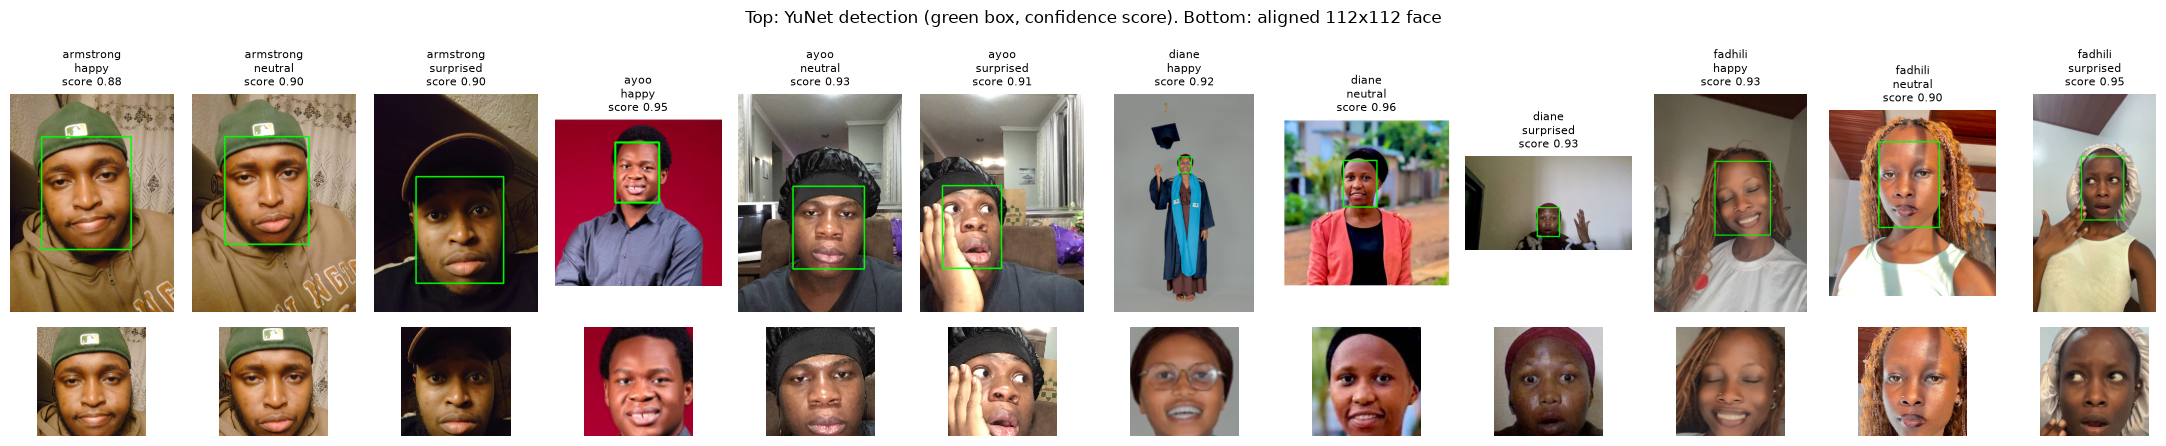

In [3]:
fig, axes = plt.subplots(2, 12, figsize=(22, 4.5), gridspec_kw={'height_ratios': [2, 1]})
for i, src in enumerate(sources.itertuples()):
    image = fm.load_image(fm.ROOT / src.source_id)
    aligned, box = fm.detect_face(image)
    x, y, w, h = box[:4].astype(int)
    shown = cv2.rectangle(image.copy(), (x, y), (x + w, y + h), (0, 255, 0), max(3, image.shape[1] // 150))
    axes[0, i].imshow(cv2.cvtColor(shown, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title(f'{src.member}\n{src.expression}\nscore {box[-1]:.2f}', fontsize=8)
    axes[1, i].imshow(cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB))
    for ax in axes[:, i]:
        ax.axis('off')
plt.suptitle('Top: YuNet detection (green box, confidence score). Bottom: aligned 112x112 face')
plt.tight_layout()
plt.show()

## 3. Augmentation

Each aligned face gets **four augmentations** in addition to the original:

| Augmentation | What it simulates |
|---|---|
| `rotate` | head tilt, random ±8–15° (reflected borders, no black corners) |
| `flip` | horizontal mirror, as with front-camera selfies |
| `grayscale` | loss of colour information / poor colour cameras |
| `brightness` | lighting change, random contrast ×0.75–1.25 and brightness ±30 |

Random parameters are seeded per image, so every run produces identical augmentations. All 60 views are saved in `processed/<member>/`. Source files are never modified.

**Important:** augmented copies are *not* new independent photos. We still have only 12 real images. The evaluation below is designed around this.

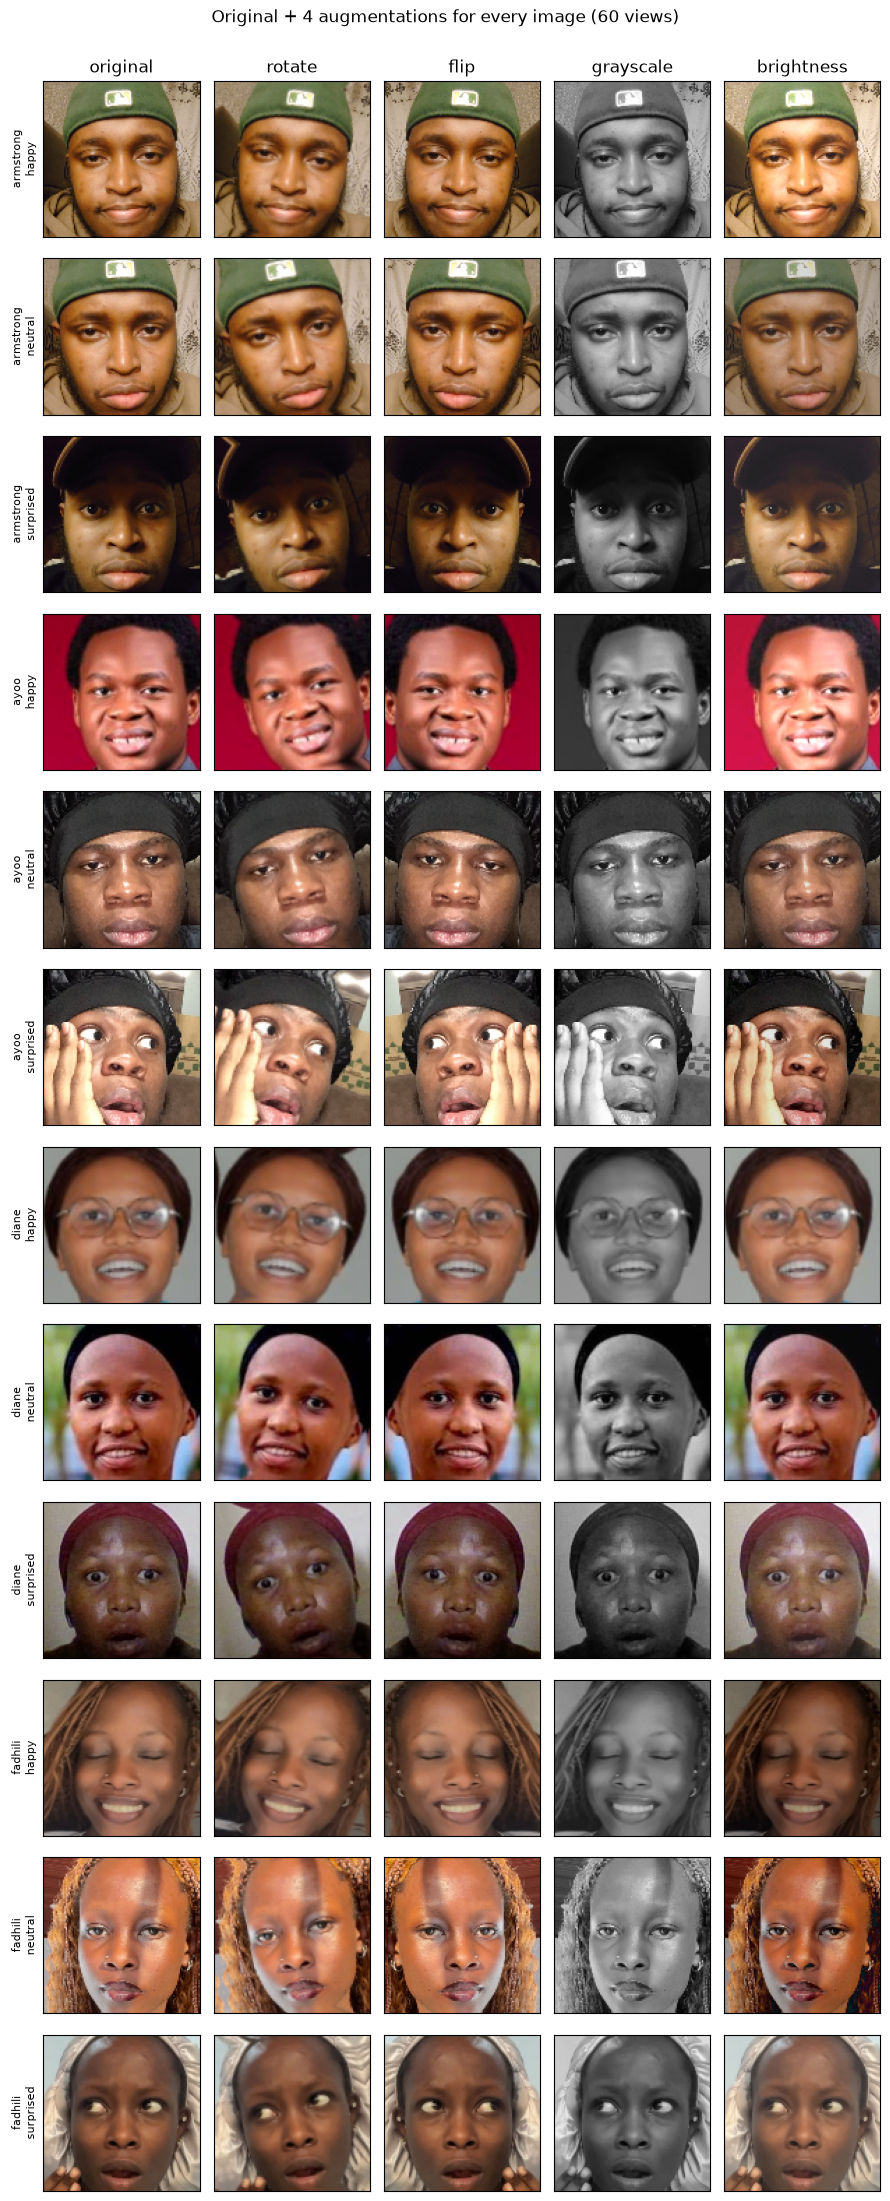

In [4]:
fig, axes = plt.subplots(len(sources), len(fm.AUGMENTATIONS), figsize=(9, 22))
for r, src in enumerate(sources.itertuples()):
    aligned, _ = fm.detect_face(fm.load_image(fm.ROOT / src.source_id))
    views = fm.augment(aligned, seed=fm.SEED + r)
    for c, (name, view) in enumerate(views.items()):
        axes[r, c].imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(name)
        if c == 0:
            axes[r, c].set_ylabel(f'{src.member}\n{src.expression}', fontsize=8)
plt.suptitle('Original + 4 augmentations for every image (60 views)', y=1.0)
plt.tight_layout()
plt.show()

## 4. Feature extraction → `image_features.csv`

For every one of the 60 views we save one row:

- `source_id, member, expression, augmentation`: metadata, so each row can be traced back to its photo
- `emb_0 … emb_127`: **SFace embedding**, L2-normalised. Faces of the same person point in similar directions, so the dot product of two embeddings is their cosine similarity.
- `hist_0 … hist_31`: normalised **32-bin grayscale intensity histogram**. Saved as a descriptive feature (it captures lighting/exposure). It is *not* used by the classifier because it describes the photo, not the person.

`fm.train()` builds the features, runs all evaluations, fits the final model, and writes every output file.

In [5]:
result = fm.train()
features, metrics = result['features'], result['metrics']

assert features.shape == (60, 4 + 128 + 32)
assert features.groupby('source_id').augmentation.nunique().eq(5).all()
assert np.isfinite(features[fm.EMB_COLS + fm.HIST_COLS].to_numpy()).all()

print(f'image_features.csv: {features.shape[0]} rows x {features.shape[1]} columns')
display(features.groupby(['member', 'augmentation']).size().unstack())
display(features.iloc[:6, :10])

image_features.csv: 60 rows x 164 columns


augmentation,brightness,flip,grayscale,original,rotate
member,,,,,
armstrong,3,3,3,3,3
ayoo,3,3,3,3,3
diane,3,3,3,3,3
fadhili,3,3,3,3,3


,source_id,member,expression,augmentation,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5
0,armstrong/armstrong_happy.jpeg,armstrong,happy,original,-0.034,-0.072,-0.116,0.041,0.003,-0.044
1,armstrong/armstrong_happy.jpeg,armstrong,happy,rotate,-0.087,-0.044,-0.109,-0.003,0.022,-0.040
2,armstrong/armstrong_happy.jpeg,armstrong,happy,flip,-0.049,-0.091,-0.142,0.006,0.025,-0.053
3,armstrong/armstrong_happy.jpeg,armstrong,happy,grayscale,-0.018,-0.092,-0.119,0.020,0.018,-0.039
4,armstrong/armstrong_happy.jpeg,armstrong,happy,brightness,-0.049,-0.085,-0.112,0.048,0.010,-0.044
5,armstrong/armstrong_neutral.jpeg,armstrong,neutral,original,-0.045,-0.046,-0.108,-0.086,0.011,0.006


### Do the embeddings separate the members?

The heatmap shows cosine similarity between the 12 original photos. Bright blocks along the diagonal mean each member's three photos resemble each other more than they resemble anyone else.
The PCA plot squeezes all 60 views (128 dimensions) into 2D. Augmented views cluster around their source photo.

same member:      mean 0.50, min 0.20
different member: mean 0.12, max 0.38


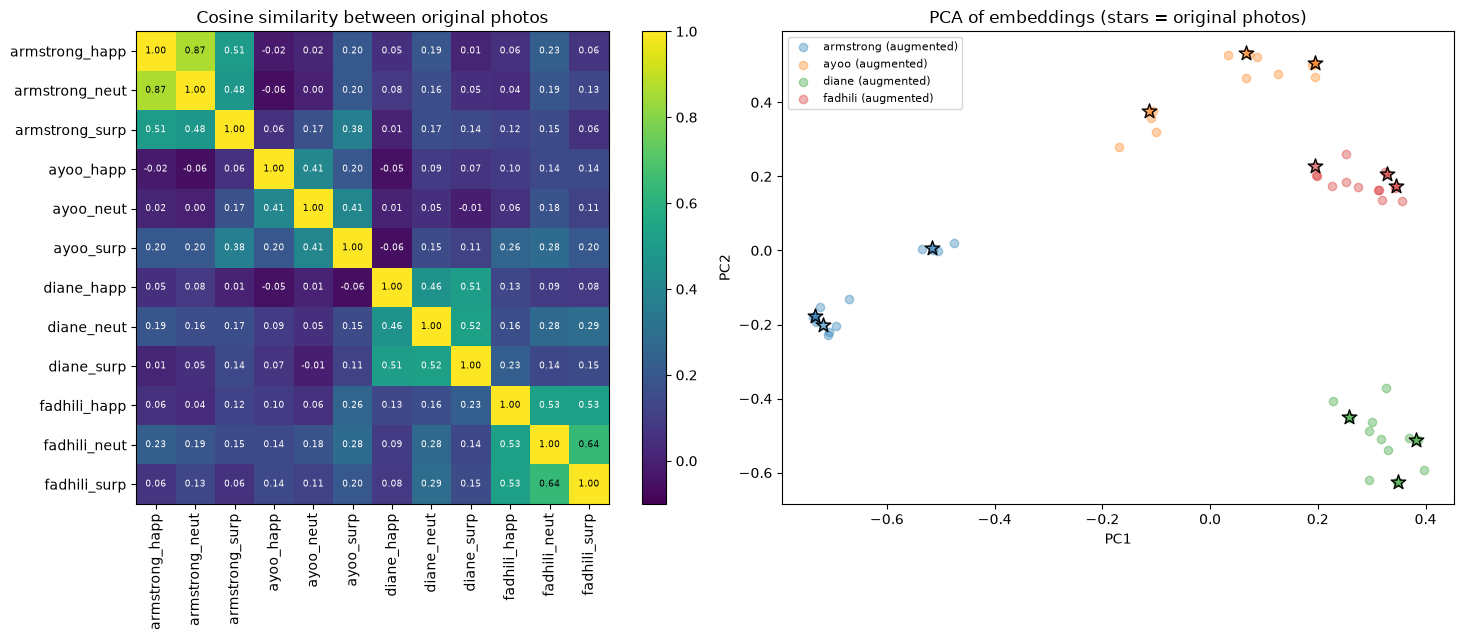

In [6]:
orig = features[features.augmentation == 'original'].reset_index(drop=True)
E = orig[fm.EMB_COLS].to_numpy()
sim = E @ E.T
labels = [f'{m}_{e[:4]}' for m, e in zip(orig.member, orig.expression)]

same = orig.member.to_numpy()[:, None] == orig.member.to_numpy()[None, :]
off_diag = ~np.eye(len(orig), dtype=bool)
print(f'same member:      mean {sim[same & off_diag].mean():.2f}, min {sim[same & off_diag].min():.2f}')
print(f'different member: mean {sim[~same].mean():.2f}, max {sim[~same].max():.2f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))
im = ax1.imshow(sim, cmap='viridis', vmin=-0.1, vmax=1)
ax1.set_xticks(range(12), labels, rotation=90); ax1.set_yticks(range(12), labels)
for i in range(12):
    for j in range(12):
        ax1.text(j, i, f'{sim[i, j]:.2f}', ha='center', va='center', fontsize=6.5,
                 color='black' if sim[i, j] > 0.6 else 'white')
ax1.set_title('Cosine similarity between original photos')
fig.colorbar(im, ax=ax1, fraction=0.046)

xy = PCA(n_components=2, random_state=fm.SEED).fit_transform(features[fm.EMB_COLS])
for member in fm.MEMBERS:
    mask = (features.member == member).to_numpy()
    o = mask & (features.augmentation == 'original').to_numpy()
    ax2.scatter(*xy[mask].T, alpha=0.35, label=f'{member} (augmented)')
    ax2.scatter(*xy[o].T, s=120, marker='*', edgecolor='black', color=ax2.collections[-1].get_facecolor()[0])
ax2.set_title('PCA of embeddings (stars = original photos)')
ax2.set_xlabel('PC1'); ax2.set_ylabel('PC2'); ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Model training and evaluation

**Classifier:** `StandardScaler` → `LogisticRegression(C=0.1)` on the 128 embedding features, This is the model used by the app. For comparison, the same evaluation is also run with a `RandomForestClassifier(300 trees)`.

**Why not a random train/test split?** If an augmented copy of a test photo lands in training, the model is effectively tested on a photo it has already seen, and scores come out falsely perfect.
We use **leave-one-expression-out cross-validation**:

| Fold | Trained on (originals + augmentations) | Tested on (originals only) |
|---|---|---|
| 1 | happy, surprised | neutral |
| 2 | neutral, surprised | happy |
| 3 | neutral, happy | surprised |

Each of the 12 photos is predicted exactly once by a model that never saw it or any of its augmentations. This also tests the harder question: *can the model recognise a member with an expression it hasn't seen?*

Metrics: **accuracy** (share of correct identities), **macro F1** (balances precision and recall, weighting each member equally), and **log loss** (penalises confident wrong answers; lower is better, ln 4 ≈ 1.39 is a random guess).

,accuracy,macro_f1,log_loss
logistic_regression,1.000,1.000,0.223
random_forest,0.917,0.914,0.687


              precision    recall  f1-score   support

   armstrong       1.00      1.00      1.00         3
        ayoo       1.00      1.00      1.00         3
       diane       1.00      1.00      1.00         3
     fadhili       1.00      1.00      1.00         3

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



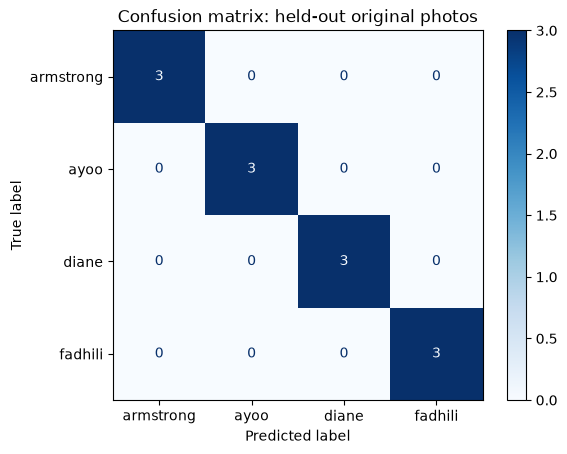

,source_id,actual,predicted,probability,similarity
0,armstrong/armstrong_neutral.jpeg,armstrong,armstrong,0.938,0.866
1,ayoo/ayoo_neutral.jpeg,ayoo,ayoo,0.900,0.415
2,diane/diane_neutral.jpeg,diane,diane,0.647,0.524
3,fadhili/fadhili_neutral.jpeg,fadhili,fadhili,0.889,0.643
4,armstrong/armstrong_happy.jpeg,armstrong,armstrong,0.969,0.866
5,ayoo/ayoo_happy.jpg,ayoo,ayoo,0.740,0.421
6,diane/diane_happy.jpeg,diane,diane,0.892,0.517
7,fadhili/fadhili_happy.jpeg,fadhili,fadhili,0.814,0.538
8,armstrong/armstrong_surprised.jpeg,armstrong,armstrong,0.680,0.524
9,ayoo/ayoo_surprised.jpeg,ayoo,ayoo,0.518,0.446


In [7]:
from sklearn.ensemble import RandomForestClassifier
_, rf_scores = fm.evaluate(features, make=lambda: RandomForestClassifier(n_estimators=300, random_state=fm.SEED))
comparison = pd.DataFrame({'logistic_regression': metrics, 'random_forest': rf_scores}).T[['accuracy', 'macro_f1', 'log_loss']]
display(comparison.astype(float).style.format('{:.3f}').set_caption('Out-of-fold scores (12 held-out photos)'))

preds = result['predictions']
print(classification_report(preds.actual, preds.predicted, zero_division=0))
ConfusionMatrixDisplay(np.array(metrics['confusion_matrix']),
                       display_labels=fm.MEMBERS).plot(cmap='Blues')
plt.title('Confusion matrix: held-out original photos')
plt.show()
display(preds)

**Interpretation.** Logistic regression identifies every held-out photo correctly. Random forest makes more mistakes and has a much higher log loss: with only 48 training rows per fold, trees split on individual embedding dimensions, while a linear model can use all 128 at once.
Note the lower confidences: `ayoo_surprised` gets only ~0.52 probability and `armstrong_surprised` ~0.68. The **surprised** expression (wide eyes, open mouth, a hand on the face) differs most from the others, which matches the similarity heatmap.

## 6. Rejecting unauthorized faces

A classifier always picks one of the four members, even for a stranger. So probability alone can't reject unknown people. We need a second check:

> **Access is granted only if** the face's cosine similarity to the predicted member's enrolled photos is ≥ a threshold.

To choose and test that threshold without photos of strangers, we use **leave-one-member-out**: train a model on three members, then show it the fourth. That person is a genuine stranger to the model.
The threshold is placed in the middle of the gap between the highest impostor score and the lowest genuine score.

threshold = 0.409
genuine accepted: 100%   strangers rejected: 100%


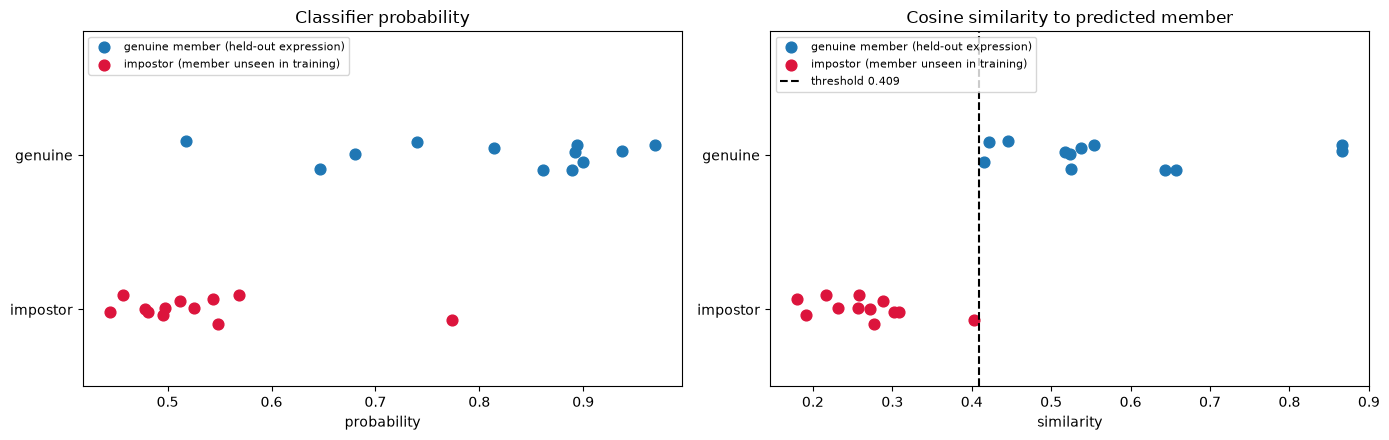

,source_id,stranger,predicted,probability,similarity
2,armstrong/armstrong_surprised.jpeg,armstrong,ayoo,0.773,0.403
5,ayoo/ayoo_surprised.jpeg,ayoo,fadhili,0.445,0.308
7,diane/diane_neutral.jpeg,diane,fadhili,0.482,0.302
10,fadhili/fadhili_neutral.jpeg,fadhili,ayoo,0.512,0.288
9,fadhili/fadhili_happy.jpeg,fadhili,ayoo,0.548,0.277


In [8]:
imp = result['impostors']
gen = result['predictions']
t = metrics['threshold']
print(f'threshold = {t:.3f}')
print(f"genuine accepted: {metrics['genuine_accepted']:.0%}   strangers rejected: {metrics['strangers_rejected']:.0%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, title in ((ax1, 'probability', 'Classifier probability'), (ax2, 'similarity', 'Cosine similarity to predicted member')):
    ax.scatter(gen[col], np.full(len(gen), 1) + np.random.default_rng(0).uniform(-.1, .1, len(gen)), s=60, label='genuine member (held-out expression)')
    ax.scatter(imp[col], np.zeros(len(imp)) + np.random.default_rng(1).uniform(-.1, .1, len(imp)), s=60, color='crimson', label='impostor (member unseen in training)')
    ax.set_yticks([0, 1], ['impostor', 'genuine']); ax.set_xlabel(col); ax.set_title(title); ax.set_ylim(-.5, 1.8)
ax2.axvline(t, color='black', ls='--', label=f'threshold {t:.3f}')
ax1.legend(fontsize=8, loc='upper left'); ax2.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()
display(imp.sort_values('similarity', ascending=False).head(5))

**Interpretation.**
- *Left:* impostors and genuine members overlap in classifier probability. One impostor (`armstrong_surprised`, with Armstrong unseen) is labelled "ayoo" with 0.77 probability, higher than some genuine predictions. A probability threshold would either let strangers in or lock members out.
- *Right:* similarity separates the two groups. All 12 genuine photos are accepted and all 12 impostors rejected.
- **The margin is thin:** the closest impostor scores 0.403 and the weakest genuine photo 0.415. The threshold is also chosen from these same 24 scores, so 100%/100% is an optimistic estimate. With a new camera or lighting, a member may sometimes need to retry. For a payment flow, rejecting a real user is safer than accepting a stranger.

## 7. System demonstration: the `predict()` interface

`face_model.predict(path)` is what the command-line app calls before allowing access to the product model:

```python
import face_model
r = face_model.predict("ayoo/ayoo_neutral.jpeg")
if r["authorized"]:
    print("Welcome", r["member"])   # -> continue to voice verification
```

From a terminal: `python face_model.py predict <image>`.

The member photos below are in the enrolled gallery, so their similarity is 1.00. This **shows the interface works but is not an evaluation** (Section 5 is the evaluation). The two `test_images/` files simulate unauthorized attempts: a picture with no face, and a face too blurred/pixelated to verify.

In [9]:
demo = ['ayoo/ayoo_neutral.jpeg', 'diane/diane_happy.jpeg',
        'test_images/unauthorized_no_face.jpg', 'test_images/unauthorized_unreadable_face.jpg']
rows = []
for path in demo:
    r = fm.predict(fm.ROOT / path)
    rows.append({'image': path, 'decision': 'GRANTED' if r['authorized'] else 'DENIED', 'member': r['member'],
                 'similarity': r['similarity'], 'probability': r['probability'], 'reason': r['reason']})
display(pd.DataFrame(rows))

# Impostor simulation in the full pipeline: drop one member from the gallery and classifier,
# then authenticate that member's photo. This is what a stranger looks like to the system.
others = features[features.member != 'fadhili']
without_fadhili = {'model': fm.make_model().fit(others[fm.EMB_COLS].to_numpy(), others.member),
                   'gallery': others[others.augmentation == 'original'],
                   'threshold': metrics['threshold']}
print('fadhili, with fadhili NOT enrolled ->', fm.predict(fm.ROOT / 'fadhili/fadhili_neutral.jpeg', saved=without_fadhili))

,image,decision,member,similarity,probability,reason
0,ayoo/ayoo_neutral.jpeg,GRANTED,ayoo,1.0,0.978,matches ayoo
1,diane/diane_happy.jpeg,GRANTED,diane,1.0,0.975,matches diane
2,test_images/unauthorized_no_face.jpg,DENIED,None,0.0,0.000,no face detected
3,test_images/unauthorized_unreadable_face.jpg,DENIED,None,0.0,0.000,no face detected


fadhili, with fadhili NOT enrolled -> {'authorized': False, 'member': None, 'probability': 0.5116279125213623, 'similarity': 0.28278863430023193, 'reason': 'too different from ayoo (0.28)'}


## 8. Output files

| File | Contents |
|---|---|
| `image_features.csv` | 60 rows (12 photos × 5 views): metadata, 128 embedding features, 32 histogram features |
| `face_model.py` | full pipeline + CLI (`train`, `predict`) |
| `face_model.joblib` | fitted classifier, enrolled faces (gallery), similarity threshold |
| `face_metrics.json` | all evaluation numbers |
| `processed/<member>/` | the 60 aligned and augmented face images |
| `models/*.onnx` | pretrained YuNet detector and SFace embedder (OpenCV model zoo) |

## 9. Limitations

- **12 independent photos.** Each wrong prediction moves accuracy by 8.3 points. Augmentation adds variety, but not new evidence.
- **Thin rejection margin** (0.403 vs 0.415), with the threshold tuned on the evaluation scores. More photos per member, taken on different days, would make it more reliable.
- **No liveness check.** A printed photo of a member would pass. Voice verification (the next step in the system) is the second factor.
- Impostors were simulated with team members. A test with real non-members' photos would be more convincing.

In [10]:
for name in ['image_features.csv', 'face_model.py', 'face_model.joblib', 'face_metrics.json']:
    p = fm.ROOT / name
    assert p.is_file(), name
    print(f'{name:35s} {p.stat().st_size:>10,} bytes')
print(f"{'processed/ images':35s} {len(list((fm.ROOT / 'processed').rglob('*.jpg'))):>10}")

image_features.csv                     117,570 bytes
face_model.py                           10,487 bytes
face_model.joblib                       17,515 bytes
face_metrics.json                          386 bytes
processed/ images                           60
